<img src="./logo_UNSAM.jpg" align="right" width="150" /> 

#### Análisis y Procesamiento de Señales

# Trabajo Práctico Nº 4 - Primeras nociones de estimación espectral
#### HOFFENREICH JULIETA


# Introducción

En esta tarea se estudia la estimación espectral de una señal senoidal contaminada con ruido, analizando cómo influyen el ruido, la desintonía respecto de los bins de la DFT y el uso de distintas ventanas sobre la estimación de amplitud y frecuencia. La señal utilizada está dada por:

$$x[n]=a_0\sin(\Omega_1 n)+n_a[n]$$

La amplitud se fija en $a_0=\sqrt{2}$, de manera que la potencia media de la senoidal sea unitaria.

La frecuencia nominal se toma como $\Omega_0=\pi/2$, que para una DFT de $N$ puntos corresponde al bin $k_0=N/4$. Sin embargo, la frecuencia real de cada realización no es exactamente la misma, sino que se define como:

$$\Omega_1=\Omega_0+f_r\frac{2\pi}{N}$$

donde $f_r$ es una variable aleatoria con distribución uniforme entre $-2$ y $2$. Por lo tanto, cada realización presenta una frecuencia distinta, desplazada hasta dos resoluciones espectrales respecto de $\Omega_0$. Como $f_r$ puede tomar valores continuos, la mayoría de las frecuencias no coincide exactamente con un bin entero de la DFT. Esto produce *desparramo espectral*, haciendo que la energía de la senoidal no quede concentrada en un único bin sino distribuida entre bins vecinos.

A la senoidal se le suma ruido gaussiano aditivo de media nula y varianza $\sigma^2$:

$$n_a[n]\sim\mathcal{N}(0,\sigma^2)$$

La potencia del ruido se ajusta para trabajar con relaciones señal a ruido de 3 dB y 10 dB. Como la potencia de la senoidal es $1$ W, la varianza del ruido puede obtenerse directamente a partir de la SNR.

Además de la ventana rectangular, se analizan las ventanas Flat-top, Blackman-Harris y Hamming. Cada ventana modifica de manera diferente el espectro: cambia el ancho del lóbulo principal, la atenuación de los lóbulos laterales y el nivel de desparramo espectral. Por este motivo, una ventana puede resultar más conveniente para estimar amplitud y otra para localizar con mayor precisión una frecuencia.

Para estudiar este comportamiento se generan $R=200$ realizaciones de $N=1000$ muestras cada una. Sobre cada realización se calculan dos estimadores. El estimador de amplitud mide el módulo del espectro en la frecuencia nominal:

$$\hat a_1^i=\left|X_w^i(\Omega_0)\right|$$

mientras que el estimador de frecuencia busca la posición en la que el módulo del espectro alcanza su máximo:

$$\hat\Omega_1^i=\arg\max_{\Omega}\left|X_w^i(\Omega)\right|$$

Como cada realización contiene una frecuencia y una secuencia de ruido diferentes, los valores obtenidos por estos estimadores también varían. Por esta razón se estudia su comportamiento estadístico mediante el sesgo y la varianza. El sesgo indica cuánto se aleja, en promedio, el estimador del valor que se desea estimar:

$$s_{\hat\theta}=E\{\hat\theta\}-\theta$$

mientras que la varianza indica qué tan dispersas se encuentran las distintas estimaciones alrededor de su media:

$$v_{\hat\theta}=E\left\{(\hat\theta-E\{\hat\theta\})^2\right\}$$

En forma experimental, los valores esperados se aproximan utilizando las medias de las 200 realizaciones. De esta manera, se podrán comparar las distintas ventanas observando tanto el desplazamiento de los estimadores respecto del valor esperado como su dispersión. Idealmente se busca un estimador con bajo sesgo y baja varianza, aunque en la práctica suele existir un compromiso entre ambas características.


# Análisis y Resultados

En primer lugar se generaron las $R=200$ realizaciones de la señal, cada una formada por $N=1000$ muestras. Para evitar utilizar un ciclo `for`, se organizaron los datos de manera matricial: el vector temporal $n$ se definió como una columna de tamaño $N\times1$, mientras que las $R$ frecuencias aleatorias se organizaron como una fila de tamaño $1\times R$.

Mediante el *broadcasting* de NumPy, el producto entre ambos permite generar directamente una matriz de tamaño $N\times R$, donde cada columna corresponde a una realización distinta de la senoidal. De esta forma, las 200 señales se generan simultáneamente.

Luego se generaron dos matrices de ruido gaussiano, una para SNR = 3 dB y otra para SNR = 10 dB, manteniendo las mismas realizaciones de frecuencia en ambos casos para poder comparar el efecto del ruido. 

Una vez obtenidas las señales con ruido, se definieron las cuatro ventanas a comparar: rectangular, Flat-top, Blackman-Harris y Hamming. Cada ventana se organizó como un vector columna de tamaño $N\times1$, de manera que al multiplicarla por la matriz de señales se aplica la misma ventana sobre las $R=200$ realizaciones mediante *broadcasting*.

Así, para cada nivel de SNR se obtuvieron cuatro matrices de señales ventaneadas, una por cada tipo de ventana. Sobre estas señales se calculó posteriormente la FFT a lo largo del eje temporal, es decir, sobre cada columna de la matriz.



In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

plt.close('all')
#%% PARAMETROS
N = 1000#muestras temps          
R = 200#realizaciones          
#tendremos 200 senales con 1000 muestras cada una
a0 = np.sqrt(2)   #amp senoidal -> potencia unitaria
omega0 = np.pi/2  #frec angular nominal
k0 = N//4 # omega0 = pi/2 corresponde al bin N/4
SNR_dB = 10  

#%% FRECUENCIAS ALEATORIAS DE LAS 200 REALIZACIONES
fr = np.random.uniform(-2, 2, R)#generamos los 200 valores aleatorio de fr  
#hasta ahora tiene forma: [200] vectir de 200 elementos, con nums entre -2 y +2
omega1 = omega0 + fr*(2*np.pi/N)#calculamos la frec ang real de cada realiz, obtenemos 200 valores dist
#tamb es un vector de 200 valores: [200] y como cada senoidal es una columna
#lo convierto en (1,R) usando RESHAPE  para despue spoder multiplicarlo por n que es de (N,1) tiempo
#entonces al multiplicar omega1.n obtenemos una matriz NxR donde cada sneoidal tiene una frec disnt
omega1 = omega1.reshape(1, R)#ahora (1,200)
n = np.arange(N).reshape(N, 1)#vector columna (1000,1)

#%% GENERO SENOIDALES
s = a0 * np.sin(n * omega1)#al multiplicar n*omega 1 --> broadcasting --> me genera una matriz N*M
#s --> {1000,200}, cada COLUM ES UNA SENAL DISTINTA
#s[:, 0] toda la primer senal
#s[:, 1] toda la segunda
#s[:, 199] la ultima

#%% RUIDO SEGUN SNR
Ps = 1
SNR1 = 3
SNR2 = 10

# -------------------------
# SNR = 3 dB
# -------------------------
sigma2_3 = Ps / (10**(SNR1/10))
sigma_3 = np.sqrt(sigma2_3)
#generamos una matriz de ruido de N*R [1000,200]
na_3 = np.random.normal(0, sigma_3, (N, R))
#cada columna tiene un ruido gausiano distinto

# -------------------------
# SNR = 10 dB
# -------------------------
sigma2_10 = Ps / (10**(SNR2/10))
sigma_10 = np.sqrt(sigma2_10)
#generamos una matriz de ruido de N*R [1000,200]
na_10 = np.random.normal(0, sigma_10, (N, R))
#cada columna tiene un ruido gausiano distinto

#%% SEÑAL FINAL

# usamos LAS MISMAS 200 senoidales para los dos SNR
# entonces la unica diferencia entre los experimentos es el nivel de ruido

x_3 = s + na_3       #tamano [1000,200]
x_10 = s + na_10     #tamano [1000,200]

#%% VENTANAS

#multiplicaremos por las 200 senoidales, queremos que sea una columna de tamano N --> [1000,1]
#despues cuando hacemos multiplicacion numpy x broadcasting replica x 200 realizaciones y logra multiplicar la ventana a las 200 x
#ENTONCES LAS GENERAMOS COMO UN VECTOR DE N ELEMENTOS

w_rect = signal.windows.boxcar(N)
w_flat = signal.windows.flattop(N)
w_black = signal.windows.blackmanharris(N)
w_ham = signal.windows.hamming(N)

# Las convertimos en vectores columna (N,1)
# para poder multiplicarlas por x, que tiene tamaño (N,R)
w_rect = w_rect.reshape(N, 1)
w_flat = w_flat.reshape(N, 1)
w_black = w_black.reshape(N, 1)
w_ham = w_ham.reshape(N, 1)


#%% APLICAMOS LAS VENTANAS
#tamano devuelto: [1000,200]
# -------------------------
# SNR = 3 dB
# -------------------------
x3_rect = x_3 * w_rect
x3_flat = x_3 * w_flat
x3_black = x_3 * w_black
x3_ham = x_3 * w_ham
# -------------------------
# SNR = 10 dB
# -------------------------
x10_rect = x_10 * w_rect
x10_flat = x_10 * w_flat
x10_black = x_10 * w_black
x10_ham = x_10 * w_ham

#%% FFT DE CADA SENAL VENTANEADA
#tenemos que transformar en el tiempo, y este se representa x columna entonces usamos axis=0
#axis=0 transforma sobre la columna
#axis=1 transforma sobre la fila

# -------------------------
# SNR = 3 dB
# -------------------------
fft3_rect = np.fft.fft(x3_rect, axis=0)
fft3_flat = np.fft.fft(x3_flat, axis=0)
fft3_black = np.fft.fft(x3_black, axis=0)
fft3_ham = np.fft.fft(x3_ham, axis=0)

# -------------------------
# SNR = 10 dB
# -------------------------
fft10_rect = np.fft.fft(x10_rect, axis=0)
fft10_flat = np.fft.fft(x10_flat, axis=0)
fft10_black = np.fft.fft(x10_black, axis=0)
fft10_ham = np.fft.fft(x10_ham, axis=0)

#seguimos con tamano [1000,200]
#TRANSFORMAMOS CADA COLUMNA DEL DOM TEMPORAL AL FRECUENCIAl
#COMO X ES REAL, EL ESPECTRO ES CONJUGADO SIMETRICO
#NOS QUEDAMOS CON LA MITAD POSITIVA

# SNR = 3 dB
mod3_rect = np.abs(fft3_rect[:N//2, :])
mod3_flat = np.abs(fft3_flat[:N//2, :])
mod3_black = np.abs(fft3_black[:N//2, :])
mod3_ham = np.abs(fft3_ham[:N//2, :])

# SNR = 10 dB
mod10_rect = np.abs(fft10_rect[:N//2, :])
mod10_flat = np.abs(fft10_flat[:N//2, :])
mod10_black = np.abs(fft10_black[:N//2, :])
mod10_ham = np.abs(fft10_ham[:N//2, :])
#ahora tamano [500,200]

Como primera observación se graficaron los espectros de las 200 realizaciones para cada ventana, únicamente para el caso de SNR = 10 dB. Veremos cómo se distribuyen los máximos alrededor de la frecuencia nominal.

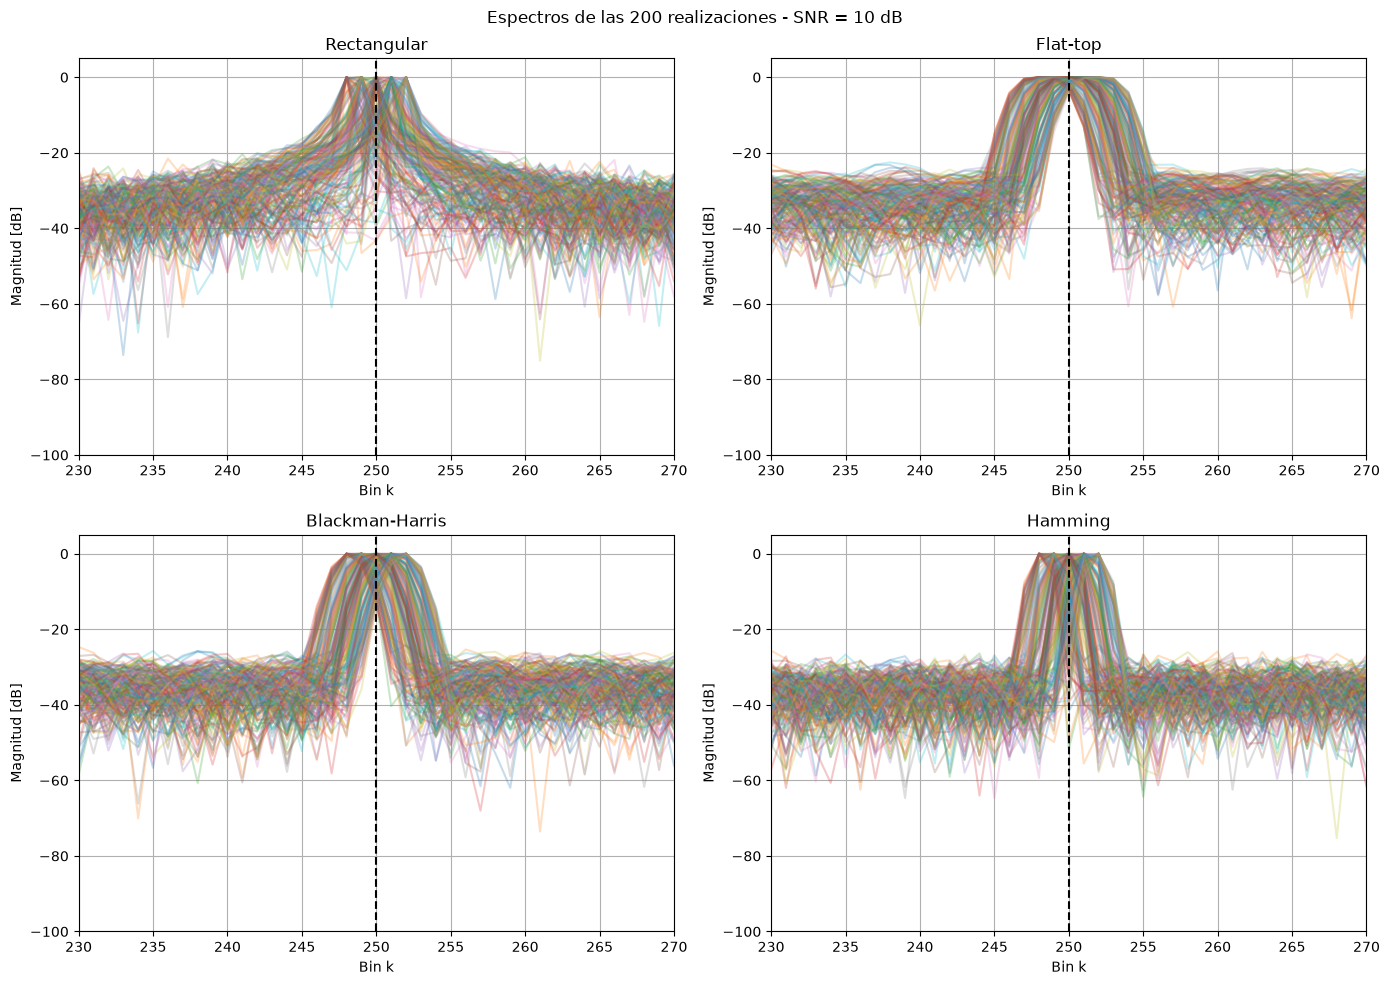

In [3]:
#%% ESPECTROS DE LAS 200 REALIZACIONES - SNR = 10 dB

k = np.arange(N//2)
plt.figure(figsize=(14,10))


# RECTANGULAR
plt.subplot(2,2,1)

for i in range(R):
    X_db = 20*np.log10(mod10_rect[:,i] / np.max(mod10_rect[:,i]) + 1e-12)
    plt.plot(k, X_db, alpha=0.25)

plt.axvline(k0, color='black', linestyle='--', linewidth=1.5)
plt.title('Rectangular')
plt.xlabel('Bin k')
plt.ylabel('Magnitud [dB]')
plt.xlim(k0-20, k0+20)
plt.ylim(-100,5)
plt.grid()

# FLAT-TOP
plt.subplot(2,2,2)
for i in range(R):
    X_db = 20*np.log10(mod10_flat[:,i] / np.max(mod10_flat[:,i]) + 1e-12)
    plt.plot(k, X_db, alpha=0.25)
plt.axvline(k0, color='black', linestyle='--', linewidth=1.5)
plt.title('Flat-top')
plt.xlabel('Bin k')
plt.ylabel('Magnitud [dB]')
plt.xlim(k0-20, k0+20)
plt.ylim(-100,5)
plt.grid()


# BLACKMAN-HARRIS

plt.subplot(2,2,3)
for i in range(R):
    X_db = 20*np.log10(mod10_black[:,i] / np.max(mod10_black[:,i]) + 1e-12)
    plt.plot(k, X_db, alpha=0.25)
plt.axvline(k0, color='black', linestyle='--', linewidth=1.5)
plt.title('Blackman-Harris')
plt.xlabel('Bin k')
plt.ylabel('Magnitud [dB]')
plt.xlim(k0-20, k0+20)
plt.ylim(-100,5)
plt.grid()

# HAMMING

plt.subplot(2,2,4)

for i in range(R):
    X_db = 20*np.log10(mod10_ham[:,i] / np.max(mod10_ham[:,i]) + 1e-12)
    plt.plot(k, X_db, alpha=0.25)
plt.axvline(k0, color='black', linestyle='--', linewidth=1.5)
plt.title('Hamming')
plt.xlabel('Bin k')
plt.ylabel('Magnitud [dB]')
plt.xlim(k0-20, k0+20)
plt.ylim(-100,5)
plt.grid()
plt.suptitle('Espectros de las 200 realizaciones - SNR = 10 dB')
plt.tight_layout()
plt.show()

Al superponer las 200 realizaciones se observa que los máximos se concentran alrededor de $k_0=250$. Como el desplazamiento aleatorio de frecuencia está comprendido entre $-2$ y $2$ resoluciones espectrales, los picos aparecen principalmente entre los bins 248 y 252.

Como la superposición de tantas realizaciones dificulta comparar la forma de las ventanas, a continuación se selecciona una única realización y se representan las cuatro ventanas en un mismo gráfico. Para esta comparación también se utiliza SNR = 10 dB, de modo que el ruido no oculte tanto la forma del lóbulo principal.

Cada espectro se normaliza respecto de su propio máximo y se expresa en dB:
$$X_{dB}=20\log_{10}\left(\frac{|X[k]|}{\max |X[k]|}\right)$$
De esta manera se compara la forma espectral de las ventanas y no su amplitud absoluta.

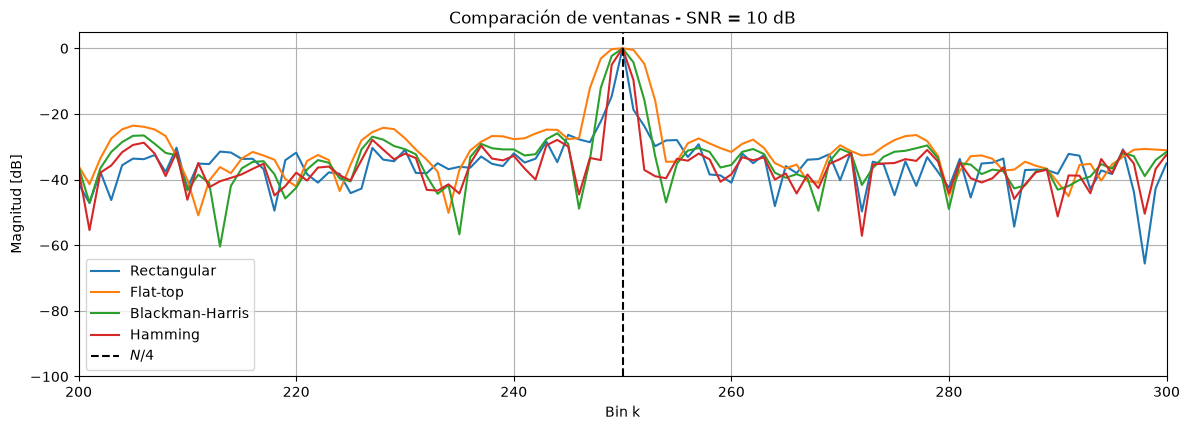

In [4]:
#%% COMPARACION DE VENTANAS EN dB - UNA REALIZACION

i = 0
k = np.arange(N//2)
# Función para pasar el espectro a dB
def espectro_db(X):
    # Seleccionamos una realizacion y normalizamos respecto de su maximo
    X_norm = X[:, i] / np.max(X[:, i])
    # Pasamos a dB
    # 1e-12 evita calcular log10(0)
    return 20 * np.log10(X_norm + 1e-12)

plt.figure(figsize=(12,8))

# SNR = 10 dB


plt.subplot(2,1,2)

plt.plot(k, espectro_db(mod10_rect), label='Rectangular')
plt.plot(k, espectro_db(mod10_flat), label='Flat-top')
plt.plot(k, espectro_db(mod10_black), label='Blackman-Harris')
plt.plot(k, espectro_db(mod10_ham), label='Hamming')

plt.axvline(k0, color='black', linestyle='--',
            linewidth=1.5, label=r'$N/4$')
plt.xlabel('Bin k')
plt.ylabel('Magnitud [dB]')
plt.title('Comparación de ventanas - SNR = 10 dB')
plt.xlim(k0-50, k0+50)
plt.ylim(-100, 5)
plt.grid()
plt.legend()
plt.tight_layout()
plt.show()


En esta representación la diferencia más clara entre las ventanas se observa en el lóbulo principal. La ventana rectangular presenta el lóbulo más angosto, mientras que Flat-top genera el más ancho y con una zona superior más plana. Blackman-Harris también ensancha el lóbulo principal y Hamming presenta un comportamiento intermedio.

El ancho del lóbulo principal es importante para la estimación de frecuencia: cuanto más angosto sea, más localizada queda la posición del máximo. La utilidad de cada ventana para los estimadores de amplitud y frecuencia se analizará luego a partir de los histogramas, el sesgo y la varianza.

## Estimación de amplitud y frecuencia
Para cada una de las $R=200$ realizaciones se calcularon los estimadores de amplitud y frecuencia. La amplitud se estimó a partir del módulo de la FFT en el bin nominal $k_0=N/4$, aplicando el mismo factor de normalización $2/N$ a todas las ventanas:
$$\hat a_1^i=\frac{2}{N}|X_w^i[k_0]|$$

La frecuencia se estimó buscando el bin en el cual el módulo de la FFT alcanza su máximo:
$$\hat k_1^i=\arg\max_k |X_w^i[k]|$$

Como se utiliza una DFT de $N$ puntos, este último estimador solo puede devolver bins enteros.

Los estimadores se calcularon para SNR = 3 dB y SNR = 10 dB. A continuación se analiza su comportamiento a partir de los histogramas y mediante el cálculo del sesgo y la varianza.

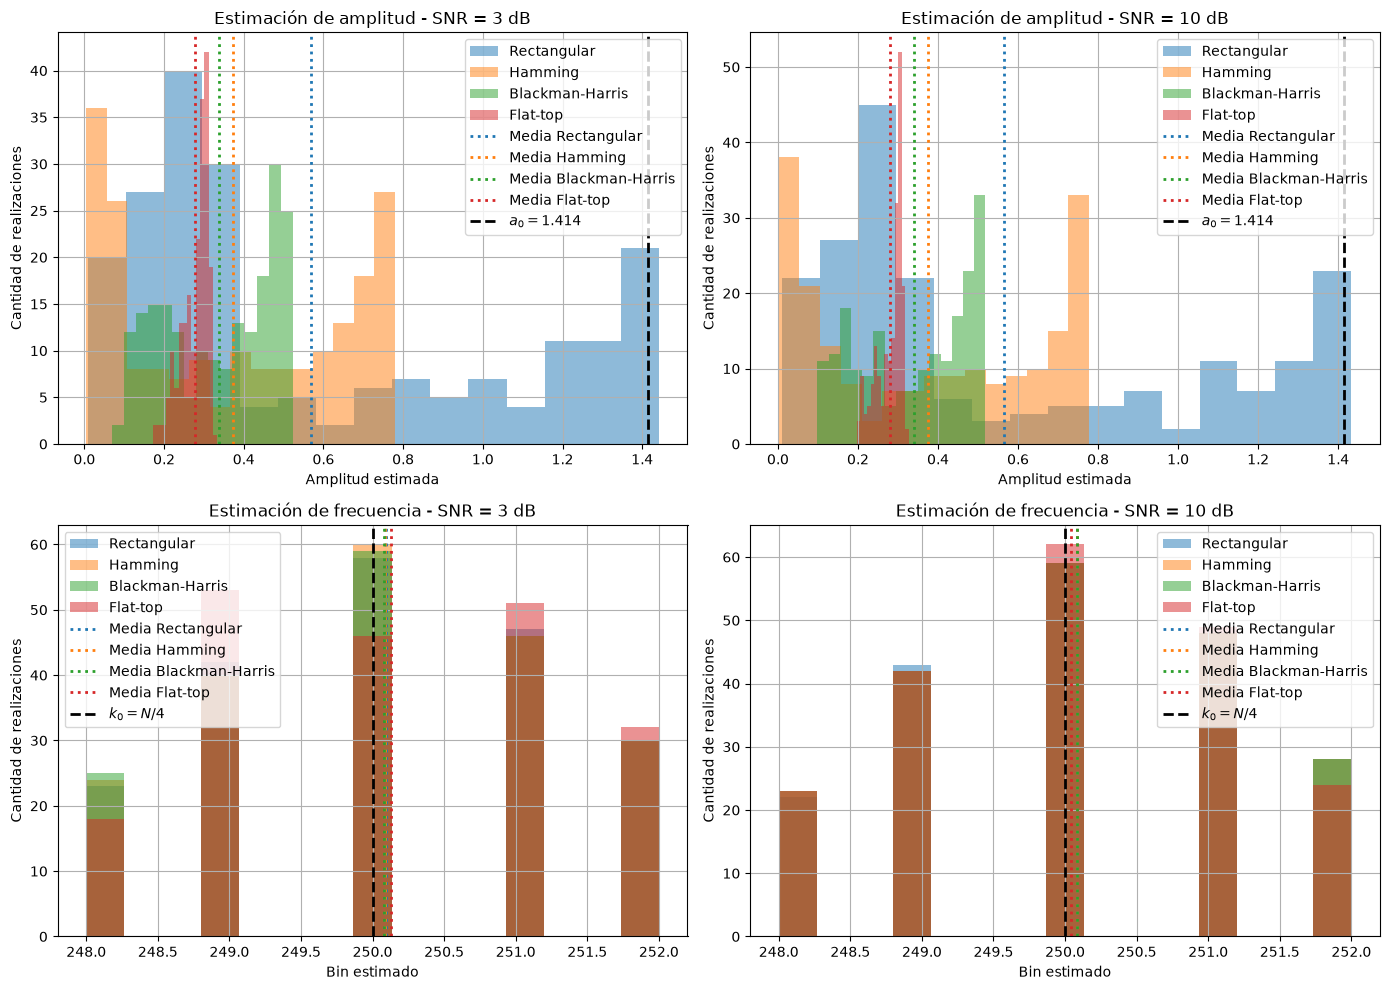

In [5]:
#%% ESTIMADORES DE AMPLITUD

# Tomamos el bin k0 = N/4 para las R realizaciones
# Como las realizaciones están en columnas, tomamos solo:
# fila k0, todas las columnas --> nos queda vector [200]
# normalizamos todas de la misma manera con 2/N

# SNR = 3 dB
est_a3_rect = (2/N) * mod3_rect[k0, :]
est_a3_flat = (2/N) * mod3_flat[k0, :]
est_a3_black = (2/N) * mod3_black[k0, :]
est_a3_ham = (2/N) * mod3_ham[k0, :]
# SNR = 10 dB
est_a10_rect = (2/N) * mod10_rect[k0, :]
est_a10_flat = (2/N) * mod10_flat[k0, :]
est_a10_black = (2/N) * mod10_black[k0, :]
est_a10_ham = (2/N) * mod10_ham[k0, :]

#%% ESTIMADORES DE FRECUENCIA

# Buscamos en qué bin está el máximo de cada realización
# axis=0 porque recorremos verticalmente los bins de frecuencia

# SNR = 3 dB
est_f3_rect = np.argmax(mod3_rect, axis=0)
est_f3_flat = np.argmax(mod3_flat, axis=0)
est_f3_black = np.argmax(mod3_black, axis=0)
est_f3_ham = np.argmax(mod3_ham, axis=0)

# SNR = 10 dB
est_f10_rect = np.argmax(mod10_rect, axis=0)
est_f10_flat = np.argmax(mod10_flat, axis=0)
est_f10_black = np.argmax(mod10_black, axis=0)
est_f10_ham = np.argmax(mod10_ham, axis=0)

bins_hist = 15
transp = 0.5

# Colores para mantener coherencia entre histograma y media
c_rect = 'C0'
c_ham = 'C1'
c_black = 'C2'
c_flat = 'C3'

plt.figure(figsize=(14,10))


# AMPLITUD - SNR = 3 dB

plt.subplot(2,2,1)

plt.hist(est_a3_rect, bins=bins_hist, alpha=transp,
         color=c_rect, label='Rectangular')
plt.hist(est_a3_ham, bins=bins_hist, alpha=transp,
         color=c_ham, label='Hamming')
plt.hist(est_a3_black, bins=bins_hist, alpha=transp,
         color=c_black, label='Blackman-Harris')
plt.hist(est_a3_flat, bins=bins_hist, alpha=transp,
         color=c_flat, label='Flat-top')

# Medias
plt.axvline(np.mean(est_a3_rect), color=c_rect,
            linestyle=':', linewidth=2,
            label='Media Rectangular')

plt.axvline(np.mean(est_a3_ham), color=c_ham,
            linestyle=':', linewidth=2,
            label='Media Hamming')

plt.axvline(np.mean(est_a3_black), color=c_black,
            linestyle=':', linewidth=2,
            label='Media Blackman-Harris')

plt.axvline(np.mean(est_a3_flat), color=c_flat,
            linestyle=':', linewidth=2,
            label='Media Flat-top')

# Verdadero valor de amplitud
plt.axvline(a0, color='black', linestyle='--',
            linewidth=2, label=fr'$a_0={a0:.3f}$')

plt.title('Estimación de amplitud - SNR = 3 dB')
plt.xlabel('Amplitud estimada')
plt.ylabel('Cantidad de realizaciones')
plt.grid()
plt.legend()


# AMPLITUD - SNR = 10 dB

plt.subplot(2,2,2)

plt.hist(est_a10_rect, bins=bins_hist, alpha=transp,
         color=c_rect, label='Rectangular')
plt.hist(est_a10_ham, bins=bins_hist, alpha=transp,
         color=c_ham, label='Hamming')
plt.hist(est_a10_black, bins=bins_hist, alpha=transp,
         color=c_black, label='Blackman-Harris')
plt.hist(est_a10_flat, bins=bins_hist, alpha=transp,
         color=c_flat, label='Flat-top')

# Medias
plt.axvline(np.mean(est_a10_rect), color=c_rect,
            linestyle=':', linewidth=2,
            label='Media Rectangular')

plt.axvline(np.mean(est_a10_ham), color=c_ham,
            linestyle=':', linewidth=2,
            label='Media Hamming')

plt.axvline(np.mean(est_a10_black), color=c_black,
            linestyle=':', linewidth=2,
            label='Media Blackman-Harris')

plt.axvline(np.mean(est_a10_flat), color=c_flat,
            linestyle=':', linewidth=2,
            label='Media Flat-top')

plt.axvline(a0, color='black', linestyle='--',
            linewidth=2, label=fr'$a_0={a0:.3f}$')

plt.title('Estimación de amplitud - SNR = 10 dB')
plt.xlabel('Amplitud estimada')
plt.ylabel('Cantidad de realizaciones')
plt.grid()
plt.legend()


# FRECUENCIA - SNR = 3 dB

plt.subplot(2,2,3)

plt.hist(est_f3_rect, bins=bins_hist, alpha=transp,
         color=c_rect, label='Rectangular')
plt.hist(est_f3_ham, bins=bins_hist, alpha=transp,
         color=c_ham, label='Hamming')
plt.hist(est_f3_black, bins=bins_hist, alpha=transp,
         color=c_black, label='Blackman-Harris')
plt.hist(est_f3_flat, bins=bins_hist, alpha=transp,
         color=c_flat, label='Flat-top')

# Medias
plt.axvline(np.mean(est_f3_rect), color=c_rect,
            linestyle=':', linewidth=2,
            label='Media Rectangular')

plt.axvline(np.mean(est_f3_ham), color=c_ham,
            linestyle=':', linewidth=2,
            label='Media Hamming')

plt.axvline(np.mean(est_f3_black), color=c_black,
            linestyle=':', linewidth=2,
            label='Media Blackman-Harris')

plt.axvline(np.mean(est_f3_flat), color=c_flat,
            linestyle=':', linewidth=2,
            label='Media Flat-top')

plt.axvline(k0, color='black', linestyle='--',
            linewidth=2, label=r'$k_0=N/4$')

plt.title('Estimación de frecuencia - SNR = 3 dB')
plt.xlabel('Bin estimado')
plt.ylabel('Cantidad de realizaciones')
plt.grid()
plt.legend()


# FRECUENCIA - SNR = 10 dB

plt.subplot(2,2,4)

plt.hist(est_f10_rect, bins=bins_hist, alpha=transp,
         color=c_rect, label='Rectangular')
plt.hist(est_f10_ham, bins=bins_hist, alpha=transp,
         color=c_ham, label='Hamming')
plt.hist(est_f10_black, bins=bins_hist, alpha=transp,
         color=c_black, label='Blackman-Harris')
plt.hist(est_f10_flat, bins=bins_hist, alpha=transp,
         color=c_flat, label='Flat-top')

# Medias
plt.axvline(np.mean(est_f10_rect), color=c_rect,
            linestyle=':', linewidth=2,
            label='Media Rectangular')

plt.axvline(np.mean(est_f10_ham), color=c_ham,
            linestyle=':', linewidth=2,
            label='Media Hamming')

plt.axvline(np.mean(est_f10_black), color=c_black,
            linestyle=':', linewidth=2,
            label='Media Blackman-Harris')

plt.axvline(np.mean(est_f10_flat), color=c_flat,
            linestyle=':', linewidth=2,
            label='Media Flat-top')

plt.axvline(k0, color='black', linestyle='--',
            linewidth=2, label=r'$k_0=N/4$')

plt.title('Estimación de frecuencia - SNR = 10 dB')
plt.xlabel('Bin estimado')
plt.ylabel('Cantidad de realizaciones')
plt.grid()
plt.legend()

plt.tight_layout()
plt.show()

A partir de estos histogramas puede analizarse visualmente el sesgo y la varianza de los estimadores: el ancho de la distribución representa su dispersión, mientras que el desplazamiento de su centro respecto del valor verdadero refleja el sesgo.

En **amplitud**, la ventana rectangular presenta estimaciones cuya media se encuentra más próxima a $a_0=\sqrt{2}$, por lo que posee un sesgo menor. Sin embargo, su distribución es más ancha, lo que indica una mayor varianza. Es decir, en este caso se obtiene poco sesgo, pero una dispersión importante.

Por otro lado, la ventana Flat-top presenta una distribución mucho más concentrada, aunque desplazada respecto del valor verdadero. Por lo tanto, posee una varianza mucho menor, pero un sesgo mayor.

Al aumentar la SNR de 3 dB a 10 dB disminuye la influencia del ruido. En amplitud, los histogramas mantienen una forma bastante similar entre ambos niveles de SNR, mientras que en frecuencia se observa una leve disminución de la dispersión para 10 dB.

En **frecuencia**, las estimaciones se concentran entre los bins 248 y 252, como era esperable por la forma en que se generaron las frecuencias. Los histogramas aparecen en posiciones discretas porque el estimador utiliza el `argmax` de una DFT de $N$ puntos y, por lo tanto, solo puede seleccionar bins enteros.

A partir de los histogramas no se observa una diferencia marcada entre las ventanas para la estimación de frecuencia. Todas presentan distribuciones bastante similares, por lo que la comparación se completa mediante el cálculo de la media, el sesgo y la varianza.

In [29]:
#%% ESTADISTICAS

# frecuencia verdadera de cada realizacion expresada en bins
# como fr esta entre -2 y +2, f_real esta entre 248 y 252
f_real = k0 + fr


# =========================================================
# SNR = 3 dB
# =========================================================

# AMPLITUD

media_a3_rect = np.mean(est_a3_rect)
media_a3_flat = np.mean(est_a3_flat)
media_a3_black = np.mean(est_a3_black)
media_a3_ham = np.mean(est_a3_ham)

sesgo_a3_rect = media_a3_rect - a0
sesgo_a3_flat = media_a3_flat - a0
sesgo_a3_black = media_a3_black - a0
sesgo_a3_ham = media_a3_ham - a0

var_a3_rect = np.var(est_a3_rect)
var_a3_flat = np.var(est_a3_flat)
var_a3_black = np.var(est_a3_black)
var_a3_ham = np.var(est_a3_ham)


# FRECUENCIA

# los estimadores est_f ya estan expresados en bins
# es decir, en multiplos de Delta f

media_f3_rect = np.mean(est_f3_rect)
media_f3_flat = np.mean(est_f3_flat)
media_f3_black = np.mean(est_f3_black)
media_f3_ham = np.mean(est_f3_ham)

# Sesgo = media estimada - media verdadera
sesgo_f3_rect = media_f3_rect - np.mean(f_real)
sesgo_f3_flat = media_f3_flat - np.mean(f_real)
sesgo_f3_black = media_f3_black - np.mean(f_real)
sesgo_f3_ham = media_f3_ham - np.mean(f_real)

# Varianza del estimador de frecuencia
var_f3_rect = np.var(est_f3_rect)
var_f3_flat = np.var(est_f3_flat)
var_f3_black = np.var(est_f3_black)
var_f3_ham = np.var(est_f3_ham)


# =========================================================
# SNR = 10 dB
# =========================================================

# AMPLITUD

media_a10_rect = np.mean(est_a10_rect)
media_a10_flat = np.mean(est_a10_flat)
media_a10_black = np.mean(est_a10_black)
media_a10_ham = np.mean(est_a10_ham)

sesgo_a10_rect = media_a10_rect - a0
sesgo_a10_flat = media_a10_flat - a0
sesgo_a10_black = media_a10_black - a0
sesgo_a10_ham = media_a10_ham - a0

var_a10_rect = np.var(est_a10_rect)
var_a10_flat = np.var(est_a10_flat)
var_a10_black = np.var(est_a10_black)
var_a10_ham = np.var(est_a10_ham)


# FRECUENCIA

media_f10_rect = np.mean(est_f10_rect)
media_f10_flat = np.mean(est_f10_flat)
media_f10_black = np.mean(est_f10_black)
media_f10_ham = np.mean(est_f10_ham)

# Sesgo = media estimada - media verdadera
sesgo_f10_rect = media_f10_rect - np.mean(f_real)
sesgo_f10_flat = media_f10_flat - np.mean(f_real)
sesgo_f10_black = media_f10_black - np.mean(f_real)
sesgo_f10_ham = media_f10_ham - np.mean(f_real)

# Varianza del estimador
var_f10_rect = np.var(est_f10_rect)
var_f10_flat = np.var(est_f10_flat)
var_f10_black = np.var(est_f10_black)
var_f10_ham = np.var(est_f10_ham)
#%% TABLAS DE RESULTADOS

def mostrar_tabla(snr,
                  media_ar, sesgo_ar, var_ar,
                  media_af, sesgo_af, var_af,
                  media_ab, sesgo_ab, var_ab,
                  media_ah, sesgo_ah, var_ah,
                  media_fr, sesgo_fr, var_fr,
                  media_ff, sesgo_ff, var_ff,
                  media_fb, sesgo_fb, var_fb,
                  media_fh, sesgo_fh, var_fh):

    print(f"\n{'='*70}")
    print(f"RESULTADOS - SNR = {snr} dB")
    print(f"{'='*70}")

    # -------------------------
    # TABLA DE AMPLITUD
    # -------------------------

    print(f"\n{'ESTIMACION DE AMPLITUD':^70}")
    print('-'*70)
    print(f"{'Ventana':<20} {'Media':>15} {'Sesgo':>15} {'Varianza':>15}")
    print('-'*70)

    print(f"{'Rectangular':<20} {media_ar:>15.6f} {sesgo_ar:>15.6f} {var_ar:>15.6f}")
    print(f"{'Flat-top':<20} {media_af:>15.6f} {sesgo_af:>15.6f} {var_af:>15.6f}")
    print(f"{'Blackman-Harris':<20} {media_ab:>15.6f} {sesgo_ab:>15.6f} {var_ab:>15.6f}")
    print(f"{'Hamming':<20} {media_ah:>15.6f} {sesgo_ah:>15.6f} {var_ah:>15.6f}")

    # -------------------------
    # TABLA DE FRECUENCIA
    # -------------------------

    print(f"\n{'ESTIMACION DE FRECUENCIA':^70}")
    print('-'*70)
    print(f"{'Ventana':<20} {'Media':>15} {'Sesgo':>15} {'Varianza':>15}")
    print('-'*70)

    print(f"{'Rectangular':<20} {media_fr:>15.6f} {sesgo_fr:>15.6f} {var_fr:>15.6f}")
    print(f"{'Flat-top':<20} {media_ff:>15.6f} {sesgo_ff:>15.6f} {var_ff:>15.6f}")
    print(f"{'Blackman-Harris':<20} {media_fb:>15.6f} {sesgo_fb:>15.6f} {var_fb:>15.6f}")
    print(f"{'Hamming':<20} {media_fh:>15.6f} {sesgo_fh:>15.6f} {var_fh:>15.6f}")


# Tabla SNR = 3 dB
mostrar_tabla(
    3,
    media_a3_rect, sesgo_a3_rect, var_a3_rect,
    media_a3_flat, sesgo_a3_flat, var_a3_flat,
    media_a3_black, sesgo_a3_black, var_a3_black,
    media_a3_ham, sesgo_a3_ham, var_a3_ham,
    media_f3_rect, sesgo_f3_rect, var_f3_rect,
    media_f3_flat, sesgo_f3_flat, var_f3_flat,
    media_f3_black, sesgo_f3_black, var_f3_black,
    media_f3_ham, sesgo_f3_ham, var_f3_ham
)

# Tabla SNR = 10 dB
mostrar_tabla(
    10,
    media_a10_rect, sesgo_a10_rect, var_a10_rect,
    media_a10_flat, sesgo_a10_flat, var_a10_flat,
    media_a10_black, sesgo_a10_black, var_a10_black,
    media_a10_ham, sesgo_a10_ham, var_a10_ham,
    media_f10_rect, sesgo_f10_rect, var_f10_rect,
    media_f10_flat, sesgo_f10_flat, var_f10_flat,
    media_f10_black, sesgo_f10_black, var_f10_black,
    media_f10_ham, sesgo_f10_ham, var_f10_ham
)



RESULTADOS - SNR = 3 dB

                        ESTIMACION DE AMPLITUD                        
----------------------------------------------------------------------
Ventana                        Media           Sesgo        Varianza
----------------------------------------------------------------------
Rectangular                 0.482150       -0.932064        0.195488
Flat-top                    0.276062       -1.138151        0.001316
Blackman-Harris             0.321097       -1.093116        0.018109
Hamming                     0.337463       -1.076750        0.069063

                       ESTIMACION DE FRECUENCIA                       
----------------------------------------------------------------------
Ventana                        Media           Sesgo        Varianza
----------------------------------------------------------------------
Rectangular               250.010000        0.128974        1.589900
Flat-top                  249.985000        0.103974        1.55

Los resultados numéricos confirman lo observado en los histogramas. En **amplitud**, la ventana Flat-top presenta la menor varianza, aunque también el mayor sesgo negativo. La rectangular presenta el menor sesgo absoluto, pero una varianza mucho mayor, mientras que Blackman-Harris y Hamming muestran comportamientos intermedios.

Todas las ventanas presentan un sesgo negativo, por lo que en promedio *subestiman* el valor verdadero $a_0=\sqrt{2}$.

Es importante tener en cuenta que el **sesgo sistemático puede corregirse mediante calibración**, mientras que la varianza no se modifica con esta corrección. Por esta razón, frente a un estimador con poco sesgo pero mucha varianza y otro con mayor sesgo pero poca varianza, puede resultar conveniente elegir el de menor varianza y posteriormente corregir su sesgo. De esta manera es posible conservar una baja dispersión y, al mismo tiempo, centrar las estimaciones alrededor del valor de referencia.
Posteriormente, se corrige el sesgo de cada estimador para observar cómo se modifican sus distribuciones luego de la calibración.

Al comparar SNR = 3 dB con SNR = 10 dB, los resultados de amplitud no cambian de manera importante, lo que indica que en este experimento el comportamiento del estimador está fuertemente condicionado por la ventana utilizada y por el desplazamiento aleatorio de la frecuencia respecto de $k_0$.

En **frecuencia**, los sesgos son pequeños para todas las ventanas y las varianzas son muy similares. En esta realización del experimento, los sesgos obtenidos son positivos, por lo que las medias estimadas se encuentran levemente por encima de la frecuencia verdadera media.

Si se comparan las varianzas, para SNR = 3 dB la menor corresponde a Blackman-Harris, mientras que para SNR = 10 dB corresponde a Flat-top. Sin embargo, las diferencias entre ventanas son pequeñas, por lo que **no aparece una única ventana claramente superior para la estimación de frecuencia**. 

## Calibración de los estimadores

Para analizar el efecto del sesgo se corrigieron las estimaciones restando el sesgo calculado:
$$\hat{\theta}_{cal}=\hat{\theta}-s_{\hat{\theta}}$$
Esta operación desplaza la distribución para centrarla en el valor de referencia, pero no modifica su varianza.

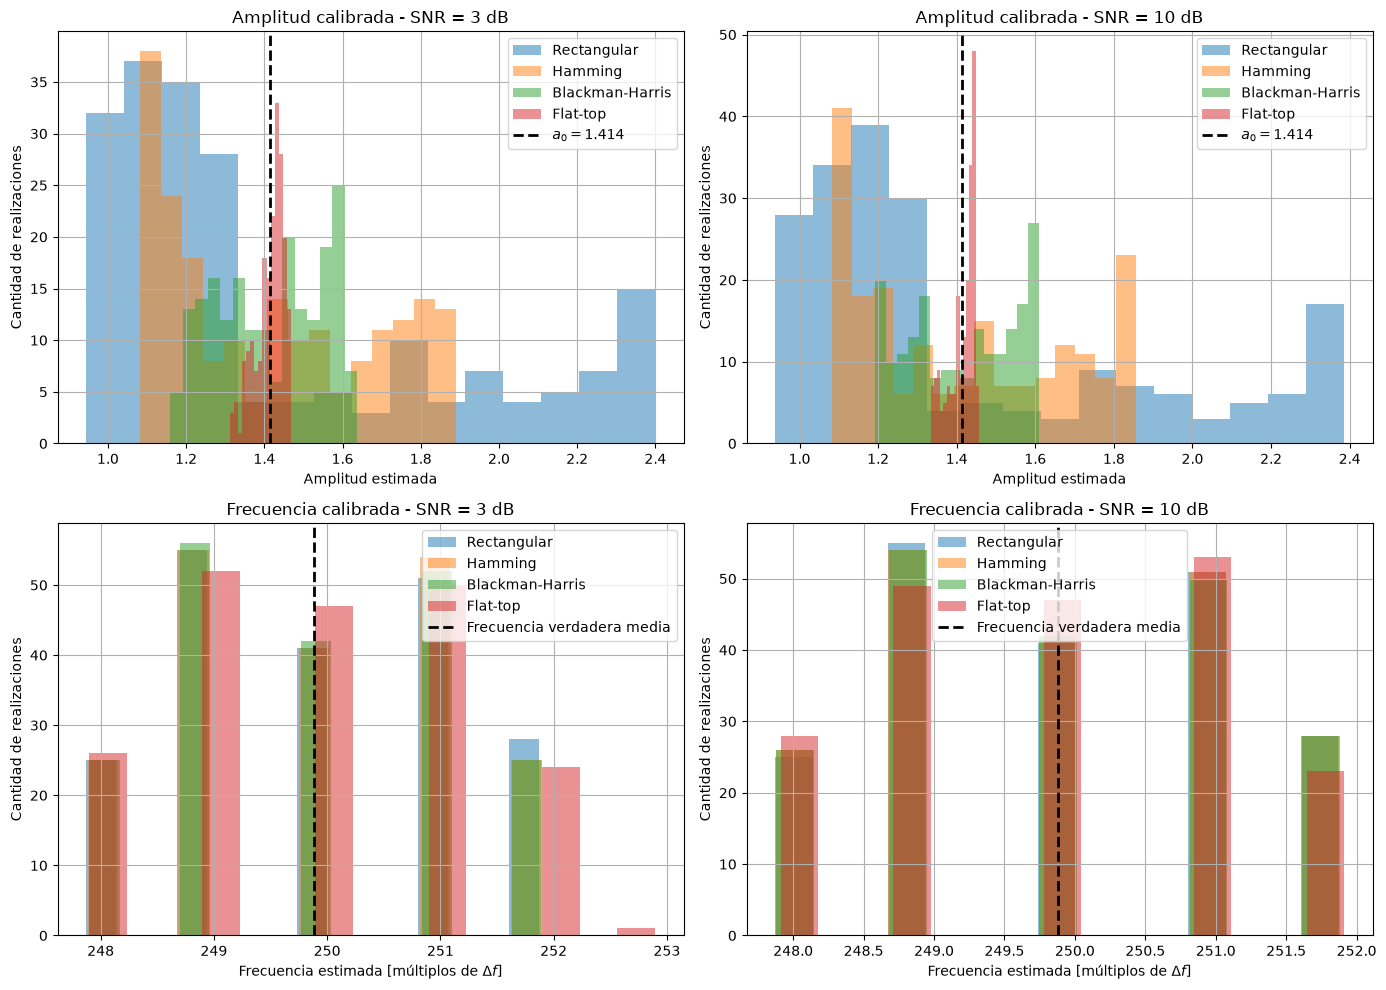

In [30]:
#%% CALIBRACION - ESTIMADORES INSESGADOS

#modificamos sesgo no varianza

# -------------------------
# SNR = 3 dB
# -------------------------

est_a3_rect_cal = est_a3_rect - sesgo_a3_rect
est_a3_flat_cal = est_a3_flat - sesgo_a3_flat
est_a3_black_cal = est_a3_black - sesgo_a3_black
est_a3_ham_cal = est_a3_ham - sesgo_a3_ham
est_f3_rect_cal = est_f3_rect - sesgo_f3_rect
est_f3_flat_cal = est_f3_flat - sesgo_f3_flat
est_f3_black_cal = est_f3_black - sesgo_f3_black
est_f3_ham_cal = est_f3_ham - sesgo_f3_ham


# -------------------------
# SNR = 10 dB
# -------------------------

est_a10_rect_cal = est_a10_rect - sesgo_a10_rect
est_a10_flat_cal = est_a10_flat - sesgo_a10_flat
est_a10_black_cal = est_a10_black - sesgo_a10_black
est_a10_ham_cal = est_a10_ham - sesgo_a10_ham
est_f10_rect_cal = est_f10_rect - sesgo_f10_rect
est_f10_flat_cal = est_f10_flat - sesgo_f10_flat
est_f10_black_cal = est_f10_black - sesgo_f10_black
est_f10_ham_cal = est_f10_ham - sesgo_f10_ham


#%% HISTOGRAMAS CALIBRADOS
#ahora las evaluamos solo x varianza, se supone que ya no hay sesgo

plt.figure(figsize=(14,10))


# -------------------------
# AMPLITUD - SNR = 3 dB
# -------------------------

plt.subplot(2,2,1)

plt.hist(est_a3_rect_cal, bins=bins_hist, alpha=transp, label='Rectangular')
plt.hist(est_a3_ham_cal, bins=bins_hist, alpha=transp, label='Hamming')
plt.hist(est_a3_black_cal, bins=bins_hist, alpha=transp, label='Blackman-Harris')
plt.hist(est_a3_flat_cal, bins=bins_hist, alpha=transp, label='Flat-top')

plt.axvline(a0, color='black', linestyle='--',
            linewidth=2, label=fr'$a_0={a0:.3f}$')

plt.title('Amplitud calibrada - SNR = 3 dB')
plt.xlabel('Amplitud estimada')
plt.ylabel('Cantidad de realizaciones')
plt.grid()
plt.legend()


# -------------------------
# AMPLITUD - SNR = 10 dB
# -------------------------

plt.subplot(2,2,2)

plt.hist(est_a10_rect_cal, bins=bins_hist, alpha=transp, label='Rectangular')
plt.hist(est_a10_ham_cal, bins=bins_hist, alpha=transp, label='Hamming')
plt.hist(est_a10_black_cal, bins=bins_hist, alpha=transp, label='Blackman-Harris')
plt.hist(est_a10_flat_cal, bins=bins_hist, alpha=transp, label='Flat-top')

plt.axvline(a0, color='black', linestyle='--',
            linewidth=2, label=fr'$a_0={a0:.3f}$')

plt.title('Amplitud calibrada - SNR = 10 dB')
plt.xlabel('Amplitud estimada')
plt.ylabel('Cantidad de realizaciones')
plt.grid()
plt.legend()


# -------------------------
# FRECUENCIA - SNR = 3 dB
# -------------------------

plt.subplot(2,2,3)

plt.hist(est_f3_rect_cal, bins=bins_hist, alpha=transp, label='Rectangular')
plt.hist(est_f3_ham_cal, bins=bins_hist, alpha=transp, label='Hamming')
plt.hist(est_f3_black_cal, bins=bins_hist, alpha=transp, label='Blackman-Harris')
plt.hist(est_f3_flat_cal, bins=bins_hist, alpha=transp, label='Flat-top')

# frecuencia verdadera media expresada en bins
plt.axvline(np.mean(f_real), color='black', linestyle='--',
            linewidth=2, label='Frecuencia verdadera media')

plt.title('Frecuencia calibrada - SNR = 3 dB')
plt.xlabel(r'Frecuencia estimada [múltiplos de $\Delta f$]')
plt.ylabel('Cantidad de realizaciones')
plt.grid()
plt.legend()


# -------------------------
# FRECUENCIA - SNR = 10 dB
# -------------------------

plt.subplot(2,2,4)

plt.hist(est_f10_rect_cal, bins=bins_hist, alpha=transp, label='Rectangular')
plt.hist(est_f10_ham_cal, bins=bins_hist, alpha=transp, label='Hamming')
plt.hist(est_f10_black_cal, bins=bins_hist, alpha=transp, label='Blackman-Harris')
plt.hist(est_f10_flat_cal, bins=bins_hist, alpha=transp, label='Flat-top')

# frecuencia verdadera media expresada en bins
plt.axvline(np.mean(f_real), color='black', linestyle='--',
            linewidth=2, label='Frecuencia verdadera media')

plt.title('Frecuencia calibrada - SNR = 10 dB')
plt.xlabel(r'Frecuencia estimada [múltiplos de $\Delta f$]')
plt.ylabel('Cantidad de realizaciones')
plt.grid()
plt.legend()


plt.tight_layout()
plt.show()


Luego de la calibración, las distribuciones de amplitud quedan centradas alrededor de $a_0=\sqrt{2}$, pero mantienen prácticamente el mismo ancho. Esto permite observar con mayor claridad que la ventana **Flat-top** es la que presenta menor dispersión y, por lo tanto, menor varianza. Al corregir su sesgo, conserva esta baja dispersión y resulta la opción *más conveniente* para la estimación de amplitud dentro de las ventanas analizadas.

En frecuencia los cambios son mucho menores porque los sesgos originales ya eran cercanos a cero. Las estimaciones continúan concentrándose en posiciones discretas, ya que la calibración corrige el desplazamiento medio pero no modifica la resolución frecuencial del estimador.

En este caso se observa que, para la estimación de amplitud, sí aparece una ventana claramente más conveniente. En cambio, para la estimación de frecuencia no se observa una ventana claramente superior. Todas presentan resultados similares, tanto en los histogramas como en los valores de sesgo y varianza obtenidos en las tablas.


## Bonus
### Efecto del zero-padding sobre el estimador de frecuencia

Para analizar el efecto del zero-padding se tomó el caso de SNR = 10 dB utilizando la ventana Flat-top. Se comparó el estimador de frecuencia obtenido con una FFT de $N$ puntos frente a una FFT de $10N$ puntos.

Sin zero-padding, la frecuencia estimada queda limitada a los bins enteros de la DFT. Por este motivo, las estimaciones se concentran únicamente en valores como 248, 249, 250, 251 y 252.

Al aplicar zero-padding hasta completar $10N$ puntos, la separación entre muestras del espectro pasa a ser:

$$\Delta f_{zp}=\frac{\Delta f}{10}$$

Por lo tanto, el máximo puede localizarse en posiciones intermedias entre los bins originales.
Se comprobó este efecto a partir del histograma y, posteriormente, sobre una única realización, comparando la frecuencia verdadera con las estimaciones obtenidas con y sin zero-padding. Los valores obtenidos se imprimieron en una tabla.



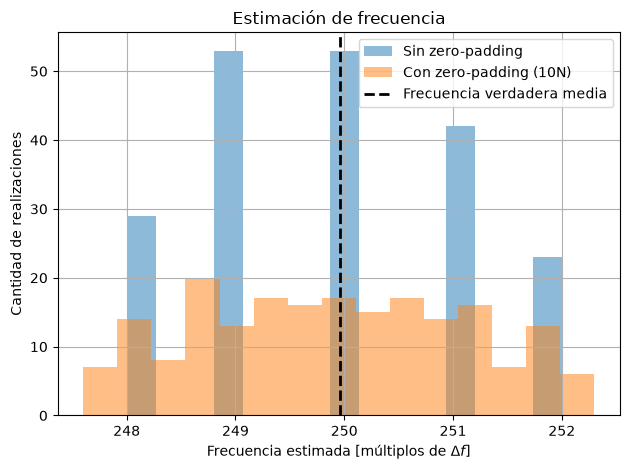

ANALISIS DEL EFECTO DEL ZERO-PADDING
Frecuencia verdadera:                  248.4859
Frecuencia estimada SIN zero-padding: 249.0000
Frecuencia estimada CON zero-padding: 248.8000


In [31]:
#%% BONUS - EFECTO DEL ZERO PADDING SOBRE EL ESTIMADOR DE FRECUENCIA

# analizamos solamente SNR = 10 dB
# usamos Flat-top para comparar antes y despues del zero-padding

N_zp = 10 * N

# FFT SIN ZERO PADDING

# ya la tenemos calculada:
# mod10_flat --> tamaño [N/2 , R]

est_f10_flat_sin_zp = np.argmax(mod10_flat, axis=0)

# FFT CON ZERO PADDING

# n=N_zp agrega ceros implicitamente hasta completar 10*N muestras
fft10_flat_zp = np.fft.fft(x10_flat, n=N_zp, axis=0)

# mitad positiva del espectro
mod10_flat_zp = np.abs(fft10_flat_zp[:N_zp//2, :])

# buscamos el maximo para cada realizacion
k_zp = np.argmax(mod10_flat_zp, axis=0)

# expresamos nuevamente el resultado en multiplos de Delta f ORIGINAL
# como tenemos 10 veces mas puntos, cada nuevo paso equivale a 0.1 Delta f
est_f10_flat_zp = k_zp * N / N_zp

# HISTOGRAMA DEL ESTIMADOR DE FRECUENCIA

plt.figure()

plt.hist(est_f10_flat_sin_zp,
         bins=15, alpha=0.5,
         label='Sin zero-padding')
plt.hist(est_f10_flat_zp,
         bins=15, alpha=0.5,
         label='Con zero-padding (10N)')
plt.axvline(f_real_media,
            color='black',
            linestyle='--',
            linewidth=2,
            label='Frecuencia verdadera media')
plt.title('Estimación de frecuencia')
plt.xlabel(r'Frecuencia estimada [múltiplos de $\Delta f$]')
plt.ylabel('Cantidad de realizaciones')
plt.grid()
plt.legend()
plt.tight_layout()
plt.show()

# Elegimos una realizacion
i = 0

# Frecuencia verdadera de esa realizacion
f_real_i = f_real[i]

# Estimacion sin zero-padding
f_est_sin_zp_i = est_f10_flat_sin_zp[i]

# Estimacion con zero-padding
f_est_con_zp_i = est_f10_flat_zp[i]

print("="*60)
print("ANALISIS DEL EFECTO DEL ZERO-PADDING")
print("="*60)

print(f"Frecuencia verdadera:                  {f_real_i:.4f}")
print(f"Frecuencia estimada SIN zero-padding: {f_est_sin_zp_i:.4f}")
print(f"Frecuencia estimada CON zero-padding: {f_est_con_zp_i:.4f}")


En el histograma se observa que, sin zero-padding, las estimaciones se concentran únicamente en bins enteros. Al utilizar $10N$ puntos aparecen valores intermedios y la distribución se vuelve mucho más continua. 
Esto ocurre porque el `argmax` continúa buscando el máximo del espectro, pero ahora lo hace sobre una grilla frecuencial diez veces más fina.

El zero-padding no agrega información nueva ni mejora la resolución real de la señal. Su efecto es proporcionar una representación más densa del espectro, permitiendo localizar el máximo con mayor precisión dentro de la forma espectral disponible.

Para una única realización, la frecuencia verdadera fue $248.4859\,\Delta f$. Sin zero-padding, el estimador tomó el valor $249\,\Delta f$, mientras que con zero-padding tomó $248.8\,\Delta f$. En este caso, la estimación con zero-padding resultó más cercana al valor verdadero.

### Estimadores alternativos
Se propusieron estimadores alternativos para la amplitud y la frecuencia, manteniendo el mismo conjunto de realizaciones utilizado anteriormente para poder comparar los resultados. En este caso, los estimadores alternativos se aplicaron directamente sobre las señales correspondientes a SNR = 10 dB.

Para la amplitud se utilizó el *valor RMS* de la señal en el dominio temporal. Para una senoidal pura se cumple:

$$A=\sqrt{2}\,x_{RMS}$$

A diferencia del estimador original, que utiliza únicamente el valor de la FFT en el bin $k_0$, el estimador RMS utiliza todas las muestras de la realización y no depende de que la frecuencia de la senoidal coincida exactamente con dicho bin.

Para la frecuencia se utilizó una *interpolación cuadrática del pico (QIP)*. En lugar de quedarse únicamente con el bin obtenido mediante `argmax`, se utilizan el máximo espectral y sus dos puntos vecinos para ajustar una parábola y estimar la posición del pico entre bins.



ESTIMADORES ALTERNATIVOS - REALIZACION 0

AMPLITUD
------------------------------------------------------------
Valor verdadero:          1.4142
Estimador FFT original:   0.1188
Estimador RMS:            1.5018

FRECUENCIA
------------------------------------------------------------
Frecuencia verdadera:     248.4859
Estimador argmax:         251.0000
Estimador QIP:            248.4140

Error argmax:             2.5141
Error QIP:                0.0718


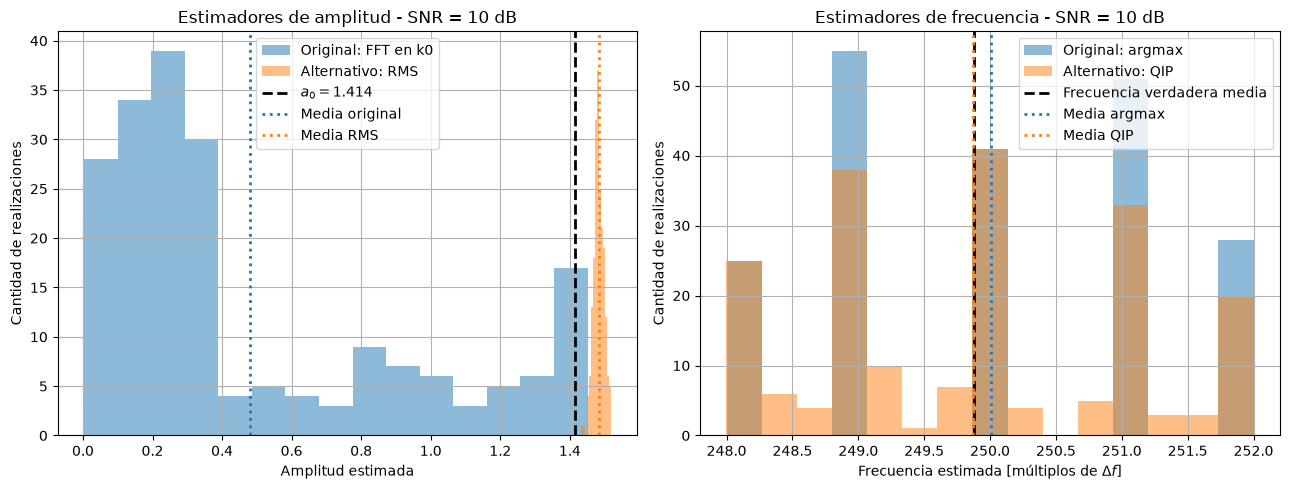


COMPARACION DE ESTIMADORES - SNR = 10 dB

ESTIMACION DE AMPLITUD
----------------------------------------------------------------------
Estimador                        Media        Sesgo     Varianza
----------------------------------------------------------------------
Original FFT                  0.479510    -0.934704     0.194274
RMS                           1.483066     0.068852     0.000217

ESTIMACION DE FRECUENCIA
----------------------------------------------------------------------
Estimador                        Media        Sesgo     Varianza
----------------------------------------------------------------------
Original argmax             250.010000     0.128974     1.589900
QIP                         249.867238    -0.013788     1.425155


In [33]:
#%% ================== ESTIMADORES ALTERNATIVOS ==================

# Analizamos solamente SNR = 10 dB


# =========================================================
# ESTIMADOR ALTERNATIVO DE AMPLITUD: RMS
# =========================================================

# Para una senoidal pura:
# RMS = A/sqrt(2)
# entonces A = sqrt(2)*RMS

# Cada columna de x_10 corresponde a una realizacion
# Calculamos un estimador de amplitud para cada una

est_a_rms = np.sqrt(2) * np.sqrt(np.mean(x_10**2, axis=0))


# =========================================================
# ESTIMADOR ALTERNATIVO DE FRECUENCIA:
# INTERPOLACION CUADRATICA DEL PICO (QIP)
# =========================================================

def estimador_qip(X):

    # Nos quedamos con la mitad positiva del espectro
    X_pos = np.abs(X[:len(X)//2])

    # Buscamos el bin donde se encuentra el maximo
    k = np.argmax(X_pos)

    # Si el maximo esta en un extremo no podemos interpolar
    if k == 0 or k == len(X_pos)-1:
        return k

    # Tomamos los tres puntos alrededor del maximo
    alpha = X_pos[k-1]
    beta  = X_pos[k]
    gamma = X_pos[k+1]

    # Interpolacion parabolica
    p = 0.5 * (alpha - gamma) / (alpha - 2*beta + gamma)

    # Posicion interpolada del maximo
    k_interp = k + p

    return k_interp


# =========================================================
# QIP PARA LAS 200 REALIZACIONES
# =========================================================

est_f_qip = np.zeros(R)

for i in range(R):

    # FFT sin zero-padding
    # De esta manera analizamos solamente el efecto
    # del nuevo estimador
    X = np.fft.fft(x_10[:, i], n=N)

    est_f_qip[i] = estimador_qip(X)


#%% ESTADISTICAS - ESTIMADORES ALTERNATIVOS


# -------------------------
# AMPLITUD RMS
# -------------------------

media_a_rms = np.mean(est_a_rms)

sesgo_a_rms = media_a_rms - a0

var_a_rms = np.var(est_a_rms)


# -------------------------
# FRECUENCIA QIP
# -------------------------

media_f_qip = np.mean(est_f_qip)

sesgo_f_qip = media_f_qip - np.mean(f_real)

var_f_qip = np.var(est_f_qip)


#%% EJEMPLO DE UNA REALIZACION

i = 0

print("\n" + "="*60)
print("ESTIMADORES ALTERNATIVOS - REALIZACION 0")
print("="*60)


print("\nAMPLITUD")
print("-"*60)

print(f"Valor verdadero:          {a0:.4f}")
print(f"Estimador FFT original:   {est_a10_rect[i]:.4f}")
print(f"Estimador RMS:            {est_a_rms[i]:.4f}")


print("\nFRECUENCIA")
print("-"*60)

print(f"Frecuencia verdadera:     {f_real[i]:.4f}")
print(f"Estimador argmax:         {est_f10_rect[i]:.4f}")
print(f"Estimador QIP:            {est_f_qip[i]:.4f}")

print(f"\nError argmax:             {abs(est_f10_rect[i] - f_real[i]):.4f}")
print(f"Error QIP:                {abs(est_f_qip[i] - f_real[i]):.4f}")


#%% COMPARACION MEDIANTE HISTOGRAMAS

plt.figure(figsize=(13,5))


# -------------------------
# AMPLITUD
# -------------------------

plt.subplot(1,2,1)

plt.hist(est_a10_rect,
         bins=15,
         alpha=0.5,
         label='Original: FFT en k0')

plt.hist(est_a_rms,
         bins=15,
         alpha=0.5,
         label='Alternativo: RMS')

plt.axvline(a0,
            color='black',
            linestyle='--',
            linewidth=2,
            label=fr'$a_0={a0:.3f}$')

plt.axvline(np.mean(est_a10_rect),
            color='C0',
            linestyle=':',
            linewidth=2,
            label='Media original')

plt.axvline(media_a_rms,
            color='C1',
            linestyle=':',
            linewidth=2,
            label='Media RMS')

plt.title('Estimadores de amplitud - SNR = 10 dB')
plt.xlabel('Amplitud estimada')
plt.ylabel('Cantidad de realizaciones')
plt.grid()
plt.legend()


# -------------------------
# FRECUENCIA
# -------------------------

plt.subplot(1,2,2)

plt.hist(est_f10_rect,
         bins=15,
         alpha=0.5,
         label='Original: argmax')

plt.hist(est_f_qip,
         bins=15,
         alpha=0.5,
         label='Alternativo: QIP')

plt.axvline(np.mean(f_real),
            color='black',
            linestyle='--',
            linewidth=2,
            label='Frecuencia verdadera media')

plt.axvline(np.mean(est_f10_rect),
            color='C0',
            linestyle=':',
            linewidth=2,
            label='Media argmax')

plt.axvline(media_f_qip,
            color='C1',
            linestyle=':',
            linewidth=2,
            label='Media QIP')

plt.title('Estimadores de frecuencia - SNR = 10 dB')
plt.xlabel(r'Frecuencia estimada [múltiplos de $\Delta f$]')
plt.ylabel('Cantidad de realizaciones')
plt.grid()
plt.legend()


plt.tight_layout()
plt.show()


#%% RESULTADOS ESTIMADORES ALTERNATIVOS

print("\n" + "="*70)
print("COMPARACION DE ESTIMADORES - SNR = 10 dB")
print("="*70)


# -------------------------
# AMPLITUD
# -------------------------

print("\nESTIMACION DE AMPLITUD")
print("-"*70)

print(f"{'Estimador':<25} {'Media':>12} {'Sesgo':>12} {'Varianza':>12}")

print("-"*70)

print(f"{'Original FFT':<25} "
      f"{media_a10_rect:>12.6f} "
      f"{sesgo_a10_rect:>12.6f} "
      f"{var_a10_rect:>12.6f}")

print(f"{'RMS':<25} "
      f"{media_a_rms:>12.6f} "
      f"{sesgo_a_rms:>12.6f} "
      f"{var_a_rms:>12.6f}")


# -------------------------
# FRECUENCIA
# -------------------------

print("\nESTIMACION DE FRECUENCIA")
print("-"*70)

print(f"{'Estimador':<25} {'Media':>12} {'Sesgo':>12} {'Varianza':>12}")

print("-"*70)

print(f"{'Original argmax':<25} "
      f"{media_f10_rect:>12.6f} "
      f"{sesgo_f10_rect:>12.6f} "
      f"{var_f10_rect:>12.6f}")

print(f"{'QIP':<25} "
      f"{media_f_qip:>12.6f} "
      f"{sesgo_f_qip:>12.6f} "
      f"{var_f_qip:>12.6f}")


En la estimación de amplitud se observa una mejora importante. El estimador original presentó una media aproximada de $0.48$, mientras que con RMS se obtuvo una media de $1.48$, mucho más cercana al valor verdadero: $a_0=\sqrt{2}\approx1.414$.

Además, el estimador RMS presentó tanto un sesgo como una varianza considerablemente menores. Por lo tanto, para este experimento resulta un estimador más adecuado de la amplitud que el basado únicamente en el valor de la FFT en $k_0$.

En cuanto a la frecuencia, para una de las realizaciones se obtuvo:

$$f_{real}=248.4859\,\Delta f$$

mientras que el estimador original basado en `argmax` dio:

$$\hat f_{argmax}=251\,\Delta f$$

y mediante QIP se obtuvo:

$$\hat f_{QIP}=248.4140\,\Delta f$$

Por lo tanto, para esta realización el error disminuyó de $2.5141\,\Delta f$ a $0.0718\,\Delta f$.

Al repetir el experimento sobre las 200 realizaciones, QIP también presentó un sesgo menor que el estimador original y permitió obtener valores intermedios entre bins. Esto se debe a que la interpolación cuadrática utiliza la forma del pico espectral para estimar su posición con mayor precisión, en lugar de limitarse al bin entero donde se encuentra el máximo.

## Conclusión

En este trabajo se analizó la estimación de amplitud y frecuencia de una señal senoidal contaminada con ruido, comparando el efecto de distintas ventanas.

Se observó que las ventanas modifican de manera importante la forma del lóbulo principal y también influyen sobre el sesgo y la varianza de los estimadores. En amplitud, la ventana rectangular presentó menor sesgo inicial, mientras que Flat-top mostró una varianza mucho menor. Luego de corregir el sesgo mediante calibración, esta baja dispersión hace que Flat-top resulte especialmente conveniente para estimar amplitud.

Para la frecuencia, los estimadores obtenidos con las distintas ventanas presentaron sesgos pequeños y varianzas similares. Por lo tanto, a diferencia de lo observado en amplitud, no se destacó una ventana claramente superior para la estimación de frecuencia, ya que todas mostraron un comportamiento bastante parecido. Además, al utilizar `argmax` sobre una DFT de $N$ puntos, las estimaciones quedan limitadas a bins enteros.

El análisis con zero-padding mostró que aumentar la cantidad de puntos de la FFT no agrega información nueva ni mejora la resolución real de la señal, pero permite evaluar el espectro sobre una grilla frecuencial más fina. Esto facilita una localización más precisa del máximo espectral.

Finalmente, los estimadores alternativos mostraron mejores resultados para este experimento. El estimador RMS permitió obtener una amplitud mucho más cercana al valor verdadero y con menor varianza, mientras que la interpolación cuadrática del pico permitió estimar frecuencias intermedias entre bins y reducir el error respecto del estimador basado únicamente en `argmax`.

En conjunto, los resultados muestran que la elección del estimador y de la ventana depende del parámetro que se quiera medir, y que el análisis de sesgo y varianza es fundamental para evaluar la calidad de una estimación.

### A destacar
El sesgo de un estimador puede corregirse mediante calibración, mientras que la varianza no se modifica con esta corrección. Por este motivo, al comparar distintos estimadores o ventanas puede resultar conveniente elegir aquel que presente menor varianza, aunque inicialmente tenga un sesgo mayor.

Una vez estimado y corregido ese sesgo, es posible obtener un estimador centrado alrededor del valor verdadero pero conservando su baja dispersión. En otras palabras, ***un estimador con gran sesgo pero poca varianza puede resultar más conveniente que uno con poco sesgo pero gran varianza, siempre que el sesgo pueda calibrarse adecuadamente***.
